In [ ]:

# ============================================
# PROYECTO: PREDICCIÓN DE RETRASOS AÉREOS
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from datetime import datetime

# Configuración
ANIO = 2025
MES = 1
N_MUESTRA = 5000

# Predeciremos 3 horas antes de la salida
HORAS_ANTICIPACION = 3

# Un vuelo se considera retrasado si sale
# 15 minutos o más después de lo programado
UMBRAL_RETRASO_MIN = 15

SEMILLA = 42

# Directorios del proyecto
BASE = Path("/content/proyecto_retrasos")

RAW = BASE / "raw"
INTERIM = BASE / "interim"
PROCESSED = BASE / "processed"
REPORTS = BASE / "reports"

for carpeta in [RAW, INTERIM, PROCESSED, REPORTS]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Configuración visual
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

print("Proyecto configurado correctamente")
print(f"Año: {ANIO}")
print(f"Mes: {MES}")
print(f"Muestra objetivo: {N_MUESTRA:,} vuelos")
print(f"Predicción: {HORAS_ANTICIPACION} horas antes")
print(f"Retraso significativo: >= {UMBRAL_RETRASO_MIN} minutos")
print(f"Carpeta: {BASE}")


Proyecto configurado correctamente
Año: 2025
Mes: 1
Muestra objetivo: 5,000 vuelos
Predicción: 3 horas antes
Retraso significativo: >= 15 minutos
Carpeta: /content/proyecto_retrasos


In [ ]:

import requests
import zipfile
import io
import time

# Archivo mensual público de BTS
nombre_archivo = f"On_Time_Reporting_Carrier_On_Time_Performance_1987_present_{ANIO}_{MES}.zip"

url = f"https://transtats.bts.gov/PREZIP/{nombre_archivo}"

ruta_zip = RAW / nombre_archivo

print("Descargando datos...")
print("Fuente:", url)

inicio = time.time()

if not ruta_zip.exists():
    respuesta = requests.get(url, timeout=180)
    respuesta.raise_for_status()

    ruta_zip.write_bytes(respuesta.content)
    print("Descarga completada")
else:
    print("El archivo ya existe. No es necesario descargarlo.")

print(f"Tamaño: {ruta_zip.stat().st_size / 1e6:.2f} MB")
print(f"Tiempo: {time.time() - inicio:.1f} segundos")

with zipfile.ZipFile(ruta_zip) as z:
    print("\nArchivos dentro del ZIP:")
    for archivo in z.namelist():
        print("-", archivo)


Descargando datos...
Fuente: https://transtats.bts.gov/PREZIP/On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2025_1.zip
El archivo ya existe. No es necesario descargarlo.
Tamaño: 27.11 MB
Tiempo: 0.0 segundos

Archivos dentro del ZIP:
- On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2025_1.csv
- readme.html


In [ ]:

with zipfile.ZipFile(ruta_zip) as z:

    archivos_csv = [
        nombre for nombre in z.namelist()
        if nombre.lower().endswith(".csv")
    ]

    if not archivos_csv:
        raise ValueError("No se encontró un archivo CSV dentro del ZIP.")

    with z.open(archivos_csv[0]) as archivo:
        # Leemos el CSV mensual.
        vuelos_mes = pd.read_csv(
            archivo,
            low_memory=False
        )

print("Registros originales:", f"{len(vuelos_mes):,}")
print("Columnas originales:", len(vuelos_mes.columns))

# Muestra reproducible
n = min(N_MUESTRA, len(vuelos_mes))

vuelos = vuelos_mes.sample(
    n=n,
    random_state=SEMILLA
).copy()

vuelos = vuelos.reset_index(drop=True)

print("\nRegistros seleccionados:", f"{len(vuelos):,}")
print("Columnas disponibles:", len(vuelos.columns))

display(vuelos.head())


Registros originales: 539,747
Columnas originales: 110

Registros seleccionados: 5,000
Columnas disponibles: 110


,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,DOT_ID_Reporting_Airline,IATA_CODE_Reporting_Airline,Tail_Number,Flight_Number_Reporting_Airline,OriginAirportID,OriginAirportSeqID,OriginCityMarketID,Origin,OriginCityName,OriginState,OriginStateFips,OriginStateName,OriginWac,DestAirportID,DestAirportSeqID,DestCityMarketID,Dest,DestCityName,DestState,DestStateFips,DestStateName,DestWac,CRSDepTime,DepTime,DepDelay,DepDelayMinutes,DepDel15,DepartureDelayGroups,DepTimeBlk,TaxiOut,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrTime,ArrDelay,ArrDelayMinutes,ArrDel15,ArrivalDelayGroups,ArrTimeBlk,Cancelled,CancellationCode,Diverted,...,LateAircraftDelay,FirstDepTime,TotalAddGTime,LongestAddGTime,DivAirportLandings,DivReachedDest,DivActualElapsedTime,DivArrDelay,DivDistance,Div1Airport,Div1AirportID,Div1AirportSeqID,Div1WheelsOn,Div1TotalGTime,Div1LongestGTime,Div1WheelsOff,Div1TailNum,Div2Airport,Div2AirportID,Div2AirportSeqID,Div2WheelsOn,Div2TotalGTime,Div2LongestGTime,Div2WheelsOff,Div2TailNum,Div3Airport,Div3AirportID,Div3AirportSeqID,Div3WheelsOn,Div3TotalGTime,Div3LongestGTime,Div3WheelsOff,Div3TailNum,Div4Airport,Div4AirportID,Div4AirportSeqID,Div4WheelsOn,Div4TotalGTime,Div4LongestGTime,Div4WheelsOff,Div4TailNum,Div5Airport,Div5AirportID,Div5AirportSeqID,Div5WheelsOn,Div5TotalGTime,Div5LongestGTime,Div5WheelsOff,Div5TailNum,Unnamed: 109
0,2025,1,1,29,3,2025-01-29,OO,20304,OO,N705SK,6279,13930,1393008,30977,ORD,"Chicago, IL",IL,17,Illinois,41,10693,1069302,30693,BNA,"Nashville, TN",TN,47,Tennessee,54,1730,1727.0,-3.0,0.0,0.0,-1.0,1700-1759,20.0,1747.0,1841.0,12.0,1900,1853.0,-7.0,0.0,0.0,-1.0,1900-1959,0.0,NaN,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025,1,1,13,1,2025-01-13,AS,19930,AS,N713AL,700,14747,1474703,30559,SEA,"Seattle, WA",WA,53,Washington,93,14107,1410702,30466,PHX,"Phoenix, AZ",AZ,4,Arizona,81,1259,1252.0,-7.0,0.0,0.0,-1.0,1200-1259,14.0,1306.0,1622.0,6.0,1650,1628.0,-22.0,0.0,0.0,-2.0,1600-1659,0.0,NaN,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025,1,1,20,1,2025-01-20,DL,19790,DL,N370NB,2970,13487,1348702,31650,MSP,"Minneapolis, MN",MN,27,Minnesota,63,11298,1129806,30194,DFW,"Dallas/Fort Worth, TX",TX,48,Texas,74,1025,1039.0,14.0,14.0,0.0,0.0,1000-1059,11.0,1050.0,1249.0,8.0,1310,1257.0,-13.0,0.0,0.0,-1.0,1300-1359,0.0,NaN,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2025,1,1,17,5,2025-01-17,WN,19393,WN,N8879Q,1289,10821,1082106,30852,BWI,"Baltimore, MD",MD,24,Maryland,35,11259,1125904,30194,DAL,"Dallas, TX",TX,48,Texas,74,845,903.0,18.0,18.0,1.0,1.0,0800-0859,11.0,914.0,1109.0,6.0,1125,1115.0,-10.0,0.0,0.0,-1.0,1100-1159,0.0,NaN,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2025,1,1,18,6,2025-01-18,G4,20368,G4,279NV,1808,10135,1013506,30135,ABE,"Allentown/Bethlehem/Easton, PA",PA,42,Pennsylvania,23,14761,1476107,34761,SFB,"Sanford, FL",FL,12,Florida,33,700,647.0,-13.0,0.0,0.0,-1.0,0700-0759,27.0,714.0,930.0,4.0,944,934.0,-10.0,0.0,0.0,-1.0,0900-0959,0.0,NaN,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:

print("=" * 60)
print("VARIABLES DEL DATASET")
print("=" * 60)

columnas = pd.DataFrame({
    "Variable": vuelos.columns,
    "Tipo": vuelos.dtypes.astype(str).values,
    "Nulos": vuelos.isna().sum().values,
    "Porcentaje_nulos": (
        vuelos.isna().mean() * 100
    ).round(2).values
})

display(columnas)

print("\nDimensiones:", vuelos.shape)
print("Duplicados completos:", vuelos.duplicated().sum())

print("\nColumnas relacionadas con retrasos:")

for columna in vuelos.columns:
    if any(palabra in columna.lower()
           for palabra in ["delay", "flight", "time", "tail"]):
        print("-", columna)


VARIABLES DEL DATASET


,Variable,Tipo,Nulos,Porcentaje_nulos
0,Year,int64,0,0.0
1,Quarter,int64,0,0.0
2,Month,int64,0,0.0
3,DayofMonth,int64,0,0.0
4,DayOfWeek,int64,0,0.0
...,...,...,...,...
105,Div5TotalGTime,float64,5000,100.0
106,Div5LongestGTime,float64,5000,100.0
107,Div5WheelsOff,float64,5000,100.0
108,Div5TailNum,float64,5000,100.0



Dimensiones: (5000, 110)
Duplicados completos: 0

Columnas relacionadas con retrasos:
- FlightDate
- Tail_Number
- Flight_Number_Reporting_Airline
- CRSDepTime
- DepTime
- DepDelay
- DepDelayMinutes
- DepartureDelayGroups
- DepTimeBlk
- CRSArrTime
- ArrTime
- ArrDelay
- ArrDelayMinutes
- ArrivalDelayGroups
- ArrTimeBlk
- CRSElapsedTime
- ActualElapsedTime
- AirTime
- Flights
- CarrierDelay
- WeatherDelay
- NASDelay
- SecurityDelay
- LateAircraftDelay
- FirstDepTime
- TotalAddGTime
- LongestAddGTime
- DivActualElapsedTime
- DivArrDelay
- Div1TotalGTime
- Div1LongestGTime
- Div1TailNum
- Div2TotalGTime
- Div2LongestGTime
- Div2TailNum
- Div3TotalGTime
- Div3LongestGTime
- Div3TailNum
- Div4TotalGTime
- Div4LongestGTime
- Div4TailNum
- Div5TotalGTime
- Div5LongestGTime
- Div5TailNum


In [ ]:

ruta_muestra = RAW / f"muestra_vuelos_{ANIO}_{MES:02d}.parquet"

vuelos.to_parquet(
    ruta_muestra,
    index=False
)

print("Muestra guardada correctamente")
print("Ruta:", ruta_muestra)
print("Registros:", len(vuelos))


Muestra guardada correctamente
Ruta: /content/proyecto_retrasos/raw/muestra_vuelos_2025_01.parquet
Registros: 5000


In [ ]:

# Crear el DataFrame para el EDA

columnas_interes = [
    "FlightDate",
    "Reporting_Airline",
    "Flight_Number_Reporting_Airline",
    "Tail_Number",
    "Origin",
    "Dest",
    "Distance",
    "CRSDepTime",
    "CRSArrTime",
    "CRSElapsedTime",
    "DepTime",
    "ArrTime",
    "DepDelay",
    "ArrDelay",
    "Cancelled",
    "Diverted",
    "CarrierDelay",
    "WeatherDelay",
    "NASDelay",
    "SecurityDelay",
    "LateAircraftDelay"
]

disponibles = [c for c in columnas_interes if c in vuelos.columns]

df = vuelos[disponibles].copy()

print("DataFrame creado correctamente")
print("Filas:", len(df))
print("Columnas:", len(df.columns))

display(df.head())


DataFrame creado correctamente
Filas: 5000
Columnas: 21


,FlightDate,Reporting_Airline,Flight_Number_Reporting_Airline,Tail_Number,Origin,Dest,Distance,CRSDepTime,CRSArrTime,CRSElapsedTime,DepTime,ArrTime,DepDelay,ArrDelay,Cancelled,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2025-01-29,OO,6279,N705SK,ORD,BNA,409.0,1730,1900,90.0,1727.0,1853.0,-3.0,-7.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,2025-01-13,AS,700,N713AL,SEA,PHX,1107.0,1259,1650,171.0,1252.0,1628.0,-7.0,-22.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
2,2025-01-20,DL,2970,N370NB,MSP,DFW,852.0,1025,1310,165.0,1039.0,1257.0,14.0,-13.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
3,2025-01-17,WN,1289,N8879Q,BWI,DAL,1209.0,845,1125,220.0,903.0,1115.0,18.0,-10.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,2025-01-18,G4,1808,279NV,ABE,SFB,882.0,700,944,164.0,647.0,934.0,-13.0,-10.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN


In [ ]:

# ============================================
# CELDA 7: DIAGNÓSTICO DE VALORES NULOS
# ============================================

columnas_revisar = [
    "FlightDate",
    "Reporting_Airline",
    "Tail_Number",
    "Origin",
    "Dest",
    "CRSDepTime",
    "CRSArrTime",
    "CRSElapsedTime",
    "Distance",
    "DepTime",
    "DepDelay",
    "ArrDelay",
    "Cancelled",
    "Diverted",
    "CarrierDelay",
    "WeatherDelay",
    "NASDelay",
    "SecurityDelay",
    "LateAircraftDelay"
]

columnas_revisar = [
    c for c in columnas_revisar if c in df.columns
]

diagnostico = pd.DataFrame({
    "Variable": columnas_revisar,
    "Nulos": [df[c].isna().sum() for c in columnas_revisar],
    "Nulos_%": [
        round(df[c].isna().mean() * 100, 2)
        for c in columnas_revisar
    ]
})

display(
    diagnostico.sort_values(
        "Nulos_%", ascending=False
    ).reset_index(drop=True)
)

# Revisar cancelaciones y desvíos
print("\nESTADO DE LOS VUELOS")

for columna in ["Cancelled", "Diverted"]:
    if columna in df.columns:
        print(f"\n{columna}:")
        display(df[columna].value_counts(dropna=False))

# Comparar los nulos del retraso con cancelaciones
if {"DepDelay", "Cancelled"}.issubset(df.columns):
    print("\nNulos de DepDelay según cancelación:")
    display(
        pd.crosstab(
            df["Cancelled"],
            df["DepDelay"].isna(),
            margins=True
        )
    )


,Variable,Nulos,Nulos_%
0,SecurityDelay,4087,81.74
1,NASDelay,4087,81.74
2,WeatherDelay,4087,81.74
3,CarrierDelay,4087,81.74
4,LateAircraftDelay,4087,81.74
5,ArrDelay,178,3.56
6,DepTime,161,3.22
7,DepDelay,161,3.22
8,Tail_Number,26,0.52
9,Reporting_Airline,0,0.00



ESTADO DE LOS VUELOS

Cancelled:


,count
Cancelled,
0.0,4836
1.0,164



Diverted:


,count
Diverted,
0.0,4986
1.0,14



Nulos de DepDelay según cancelación:


DepDelay,False,True,All
Cancelled,,,
0.0,4836,0,4836
1.0,3,161,164
All,4839,161,5000


In [ ]:

# ============================================
# CELDA 8: CANCELACIONES Y DESVÍOS
# ============================================

print("TOTAL DE VUELOS:", len(df))

print("\nESTADO DE LOS VUELOS")
print("-" * 45)

for columna in ["Cancelled", "Diverted"]:
    print(f"\n{columna}:")
    display(
        df[columna].value_counts(
            dropna=False
        ).to_frame("Cantidad")
    )

print("\nRELACIÓN ENTRE CANCELACIONES Y NULOS")
print("-" * 45)

tabla = pd.crosstab(
    df["Cancelled"],
    df["DepDelay"].isna(),
    margins=True
)

display(tabla)

print("\nREVISIÓN DE VUELOS SIN HORA REAL DE SALIDA")

columnas = [
    "FlightDate",
    "Origin",
    "Dest",
    "Cancelled",
    "Diverted",
    "DepTime",
    "DepDelay",
    "ArrDelay"
]

display(
    df.loc[
        df["DepTime"].isna(),
        columnas
    ].head(15)
)


TOTAL DE VUELOS: 5000

ESTADO DE LOS VUELOS
---------------------------------------------

Cancelled:


,Cantidad
Cancelled,
0.0,4836
1.0,164



Diverted:


,Cantidad
Diverted,
0.0,4986
1.0,14



RELACIÓN ENTRE CANCELACIONES Y NULOS
---------------------------------------------


DepDelay,False,True,All
Cancelled,,,
0.0,4836,0,4836
1.0,3,161,164
All,4839,161,5000



REVISIÓN DE VUELOS SIN HORA REAL DE SALIDA


,FlightDate,Origin,Dest,Cancelled,Diverted,DepTime,DepDelay,ArrDelay
38,2025-01-22,DAL,HOU,1.0,0.0,NaN,NaN,NaN
64,2025-01-09,DFW,CLT,1.0,0.0,NaN,NaN,NaN
93,2025-01-31,HNL,PDX,1.0,0.0,NaN,NaN,NaN
97,2025-01-30,SAF,DFW,1.0,0.0,NaN,NaN,NaN
115,2025-01-19,IAD,CLE,1.0,0.0,NaN,NaN,NaN
186,2025-01-21,ATL,CLT,1.0,0.0,NaN,NaN,NaN
230,2025-01-11,GSO,LGA,1.0,0.0,NaN,NaN,NaN
240,2025-01-05,RSW,STL,1.0,0.0,NaN,NaN,NaN
248,2025-01-23,BWI,CHS,1.0,0.0,NaN,NaN,NaN
253,2025-01-06,LGA,BNA,1.0,0.0,NaN,NaN,NaN


Vuelos originales: 5000
Vuelos disponibles para modelado: 4836
Vuelos excluidos: 164

DISTRIBUCIÓN DE LA VARIABLE OBJETIVO


,Vuelos,Porcentaje
retraso_15,,
Sin retraso significativo,3940,81.47
Con retraso >=15 min,896,18.53


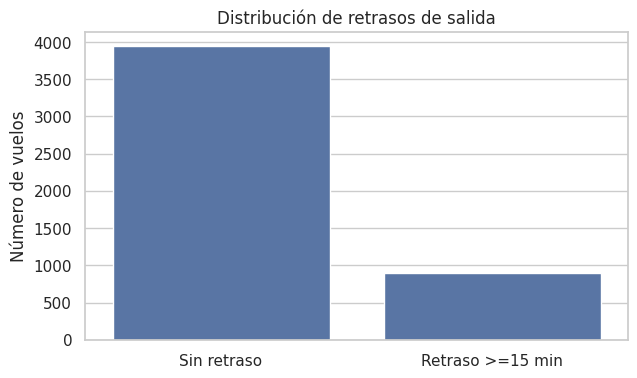

In [ ]:

# ============================================
# CELDA 9: VARIABLE OBJETIVO
# ============================================

# Conservamos únicamente vuelos que operaron
# y tienen un retraso de salida registrado.

df_modelo = df[
    (df["Cancelled"] == 0) &
    (df["DepDelay"].notna())
].copy()

# Variable objetivo:
# 1 = salió 15 minutos o más tarde
# 0 = salió con menos de 15 minutos de retraso

df_modelo["retraso_15"] = (
    df_modelo["DepDelay"] >= 15
).astype(int)

print("Vuelos originales:", len(df))
print("Vuelos disponibles para modelado:", len(df_modelo))
print("Vuelos excluidos:", len(df) - len(df_modelo))

print("\nDISTRIBUCIÓN DE LA VARIABLE OBJETIVO")

resumen = pd.DataFrame({
    "Vuelos": df_modelo["retraso_15"].value_counts(),
    "Porcentaje": (
        df_modelo["retraso_15"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

resumen.index = resumen.index.map({
    0: "Sin retraso significativo",
    1: "Con retraso >=15 min"
})

display(resumen)

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df_modelo,
    x="retraso_15",
    order=[0, 1]
)

plt.xticks(
    [0, 1],
    ["Sin retraso", "Retraso >=15 min"]
)

plt.title("Distribución de retrasos de salida")
plt.xlabel("")
plt.ylabel("Número de vuelos")
plt.show()


,hora_salida,vuelos,retrasados,tasa_retraso
0,0,5,0,0.00
1,1,5,1,20.00
2,2,1,1,100.00
3,3,1,1,100.00
4,5,119,9,7.56
5,6,329,31,9.42
6,7,354,37,10.45
7,8,344,38,11.05
8,9,263,40,15.21
9,10,279,60,21.51


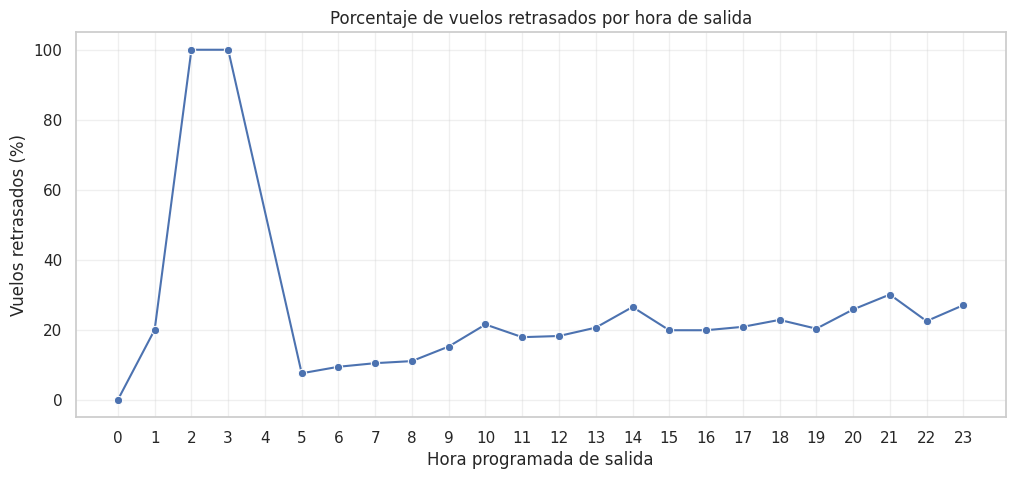

In [ ]:

# ============================================
# CELDA 10: RETRASOS POR HORA PROGRAMADA
# ============================================

# Convertimos CRSDepTime (formato HHMM) a hora
df_modelo["hora_salida"] = (
    pd.to_numeric(
        df_modelo["CRSDepTime"],
        errors="coerce"
    ) // 100
)

# Agrupamos por hora
retrasos_hora = (
    df_modelo.groupby("hora_salida")
    .agg(
        vuelos=("retraso_15", "size"),
        retrasados=("retraso_15", "sum"),
        tasa_retraso=("retraso_15", "mean")
    )
    .reset_index()
)

retrasos_hora["tasa_retraso"] *= 100

display(retrasos_hora.round(2))

# Visualización
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=retrasos_hora,
    x="hora_salida",
    y="tasa_retraso",
    marker="o"
)

plt.title("Porcentaje de vuelos retrasados por hora de salida")
plt.xlabel("Hora programada de salida")
plt.ylabel("Vuelos retrasados (%)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.show()


,hora_salida,vuelos,retrasados,tasa_retraso
0,0,5,0,0.00
1,1,5,1,20.00
2,2,1,1,100.00
3,3,1,1,100.00
4,5,119,9,7.56
5,6,329,31,9.42
6,7,354,37,10.45
7,8,344,38,11.05
8,9,263,40,15.21
9,10,279,60,21.51


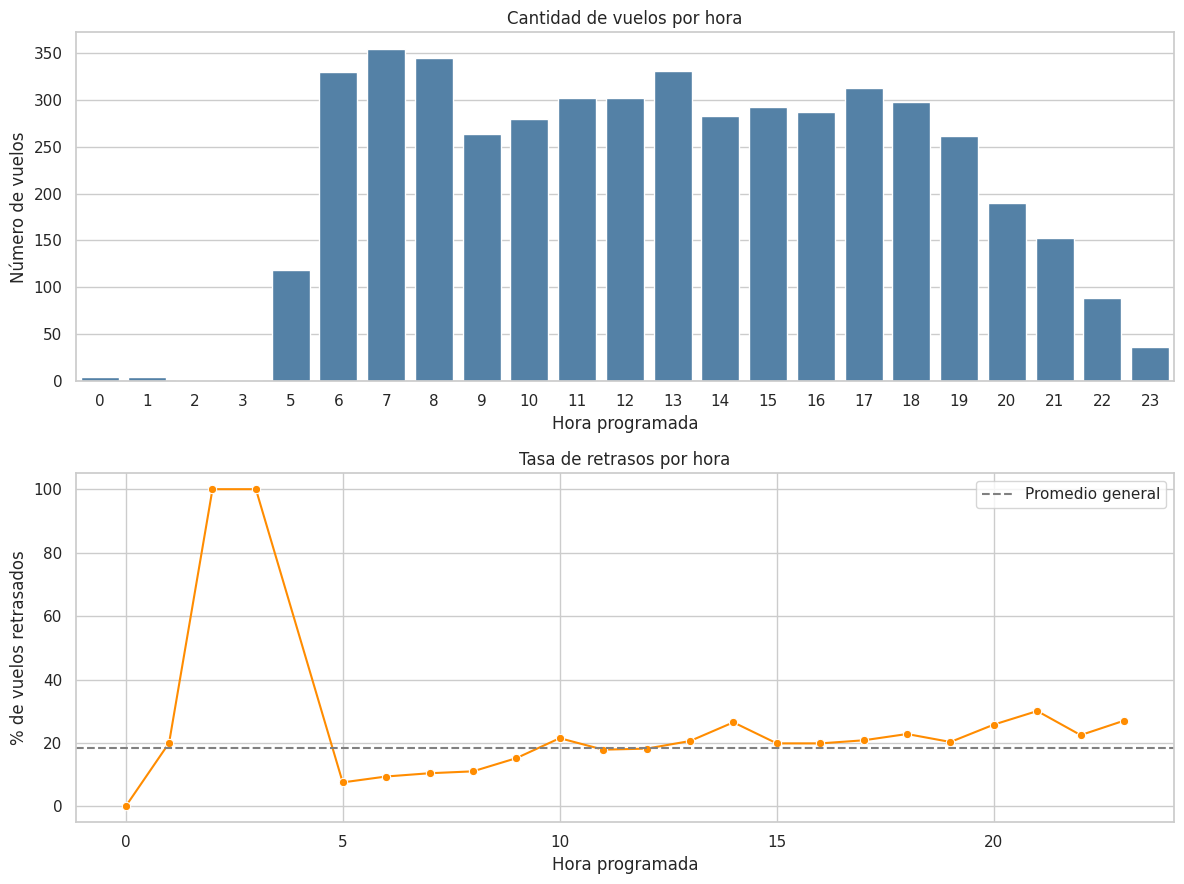


HORAS CON MENOS DE 30 VUELOS:


,hora_salida,vuelos,retrasados,tasa_retraso
0,0,5,0,0.0
1,1,5,1,20.0
2,2,1,1,100.0
3,3,1,1,100.0


In [ ]:

# ============================================
# CELDA 11: VOLUMEN Y RETRASOS POR HORA
# ============================================

resumen_hora = (
    df_modelo.groupby("hora_salida")
    .agg(
        vuelos=("retraso_15", "size"),
        retrasados=("retraso_15", "sum"),
        tasa_retraso=("retraso_15", "mean")
    )
    .reset_index()
)

resumen_hora["tasa_retraso"] *= 100

display(resumen_hora.round(2))

# Gráficas separadas
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

# Número de vuelos
sns.barplot(
    data=resumen_hora,
    x="hora_salida",
    y="vuelos",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Cantidad de vuelos por hora")
axes[0].set_xlabel("Hora programada")
axes[0].set_ylabel("Número de vuelos")

# Porcentaje de retrasos
sns.lineplot(
    data=resumen_hora,
    x="hora_salida",
    y="tasa_retraso",
    marker="o",
    color="darkorange",
    ax=axes[1]
)

axes[1].axhline(
    df_modelo["retraso_15"].mean() * 100,
    linestyle="--",
    color="gray",
    label="Promedio general"
)

axes[1].set_title("Tasa de retrasos por hora")
axes[1].set_xlabel("Hora programada")
axes[1].set_ylabel("% de vuelos retrasados")
axes[1].legend()

plt.tight_layout()
plt.show()

print("\nHORAS CON MENOS DE 30 VUELOS:")
display(
    resumen_hora[
        resumen_hora["vuelos"] < 30
    ].round(2)
)


,Origin,vuelos,retrasados,tasa_retraso
62,DEN,260,65,25.00
63,DFW,227,59,25.99
11,ATL,210,52,24.76
168,ORD,173,39,22.54
48,CLT,155,29,18.71
176,PHX,143,23,16.08
128,LAX,134,16,11.94
126,LAS,129,23,17.83
141,MCO,109,28,25.69
28,BOS,108,17,15.74


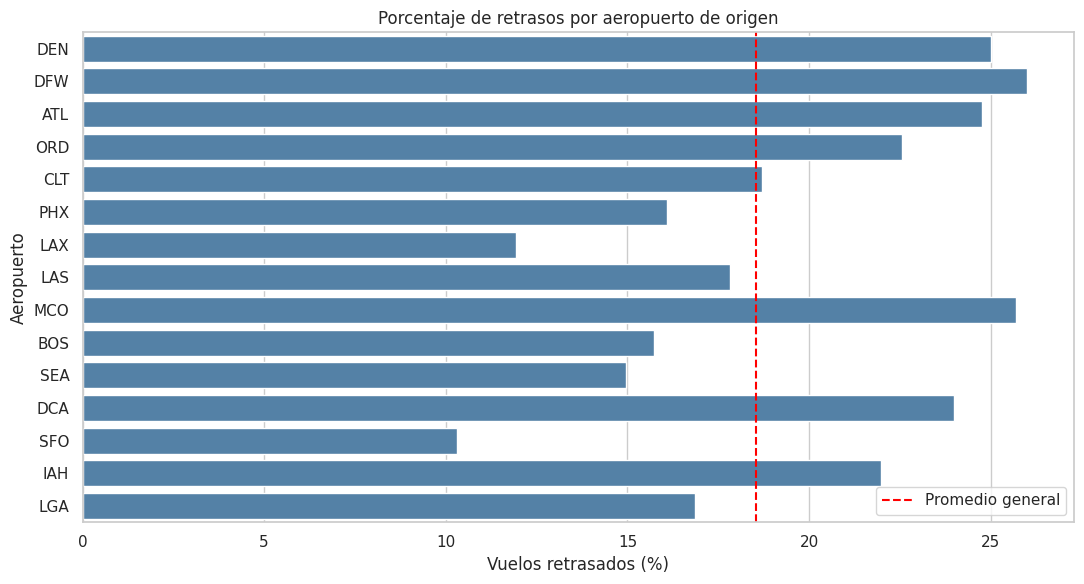

Aeropuertos totales: 245
Aeropuertos con al menos 30 vuelos: 46


In [ ]:

# ============================================
# CELDA 12: RETRASOS POR AEROPUERTO
# ============================================

aeropuertos = (
    df_modelo.groupby("Origin")
    .agg(
        vuelos=("retraso_15", "size"),
        retrasados=("retraso_15", "sum"),
        tasa_retraso=("retraso_15", "mean")
    )
    .reset_index()
)

aeropuertos["tasa_retraso"] *= 100

# Filtramos aeropuertos con suficiente muestra
aeropuertos_validos = aeropuertos[
    aeropuertos["vuelos"] >= 30
].copy()

# Seleccionamos los 15 con mayor volumen
top_aeropuertos = (
    aeropuertos_validos
    .sort_values("vuelos", ascending=False)
    .head(15)
)

display(top_aeropuertos.round(2))

# Visualización
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_aeropuertos,
    x="tasa_retraso",
    y="Origin",
    color="steelblue"
)

plt.axvline(
    df_modelo["retraso_15"].mean() * 100,
    color="red",
    linestyle="--",
    label="Promedio general"
)

plt.title("Porcentaje de retrasos por aeropuerto de origen")
plt.xlabel("Vuelos retrasados (%)")
plt.ylabel("Aeropuerto")
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Aeropuertos totales:",
    df_modelo["Origin"].nunique()
)

print(
    "Aeropuertos con al menos 30 vuelos:",
    len(aeropuertos_validos)
)


,Reporting_Airline,vuelos,retrasados,tasa_retraso
12,WN,901,144,15.98
3,DL,688,131,19.04
0,AA,670,137,20.45
10,OO,626,122,19.49
11,UA,559,99,17.71
13,YX,232,25,10.78
7,MQ,196,26,13.27
9,OH,181,40,22.10
1,AS,171,29,16.96
8,NK,158,32,20.25


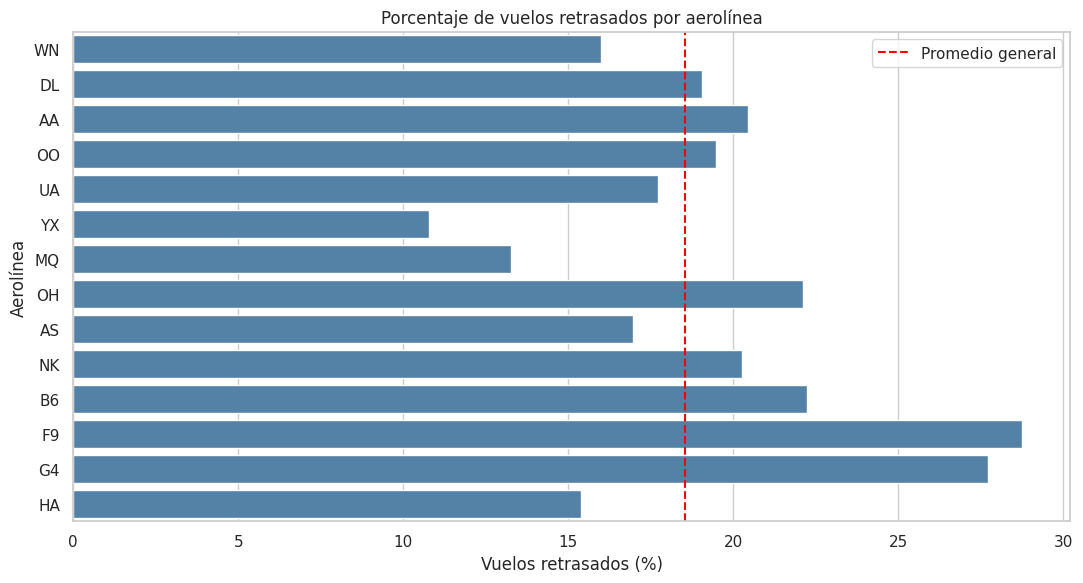

In [ ]:

# ============================================
# CELDA 13: RETRASOS POR AEROLÍNEA
# ============================================

aerolineas = (
    df_modelo.groupby("Reporting_Airline")
    .agg(
        vuelos=("retraso_15", "size"),
        retrasados=("retraso_15", "sum"),
        tasa_retraso=("retraso_15", "mean")
    )
    .reset_index()
)

aerolineas["tasa_retraso"] *= 100

aerolineas = aerolineas.sort_values(
    "vuelos", ascending=False
)

display(aerolineas.round(2))

# Gráfica
plt.figure(figsize=(11, 6))

sns.barplot(
    data=aerolineas,
    x="tasa_retraso",
    y="Reporting_Airline",
    color="steelblue"
)

plt.axvline(
    df_modelo["retraso_15"].mean() * 100,
    color="red",
    linestyle="--",
    label="Promedio general"
)

plt.title("Porcentaje de vuelos retrasados por aerolínea")
plt.xlabel("Vuelos retrasados (%)")
plt.ylabel("Aerolínea")
plt.legend()
plt.tight_layout()
plt.show()


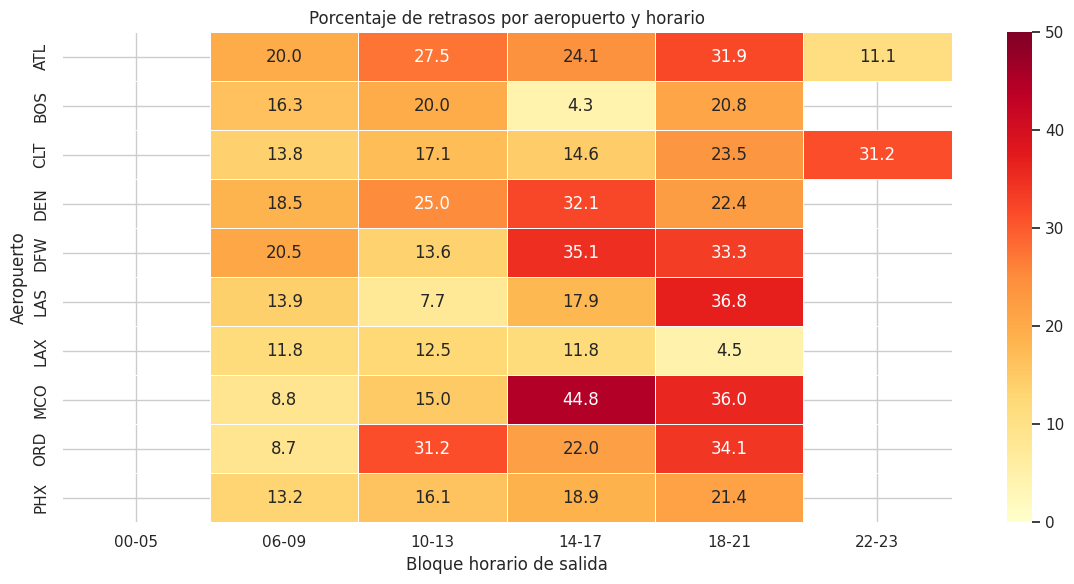

Cantidad de vuelos por combinación:


bloque_horario,00-05,06-09,10-13,14-17,18-21,22-23
Origin,,,,,,
ATL,NaN,40.0,51.0,54.0,47.0,18.0
BOS,3.0,43.0,15.0,23.0,24.0,NaN
CLT,NaN,29.0,35.0,41.0,34.0,16.0
DEN,1.0,54.0,84.0,56.0,58.0,7.0
DFW,1.0,39.0,59.0,57.0,69.0,2.0
LAS,4.0,36.0,26.0,39.0,19.0,5.0
LAX,4.0,51.0,32.0,17.0,22.0,8.0
MCO,1.0,34.0,20.0,29.0,25.0,NaN
ORD,4.0,46.0,32.0,50.0,41.0,NaN


In [ ]:

# ============================================
# CELDA 14: AEROPUERTO VS HORA DE SALIDA
# ============================================

# Seleccionar los 10 aeropuertos con más vuelos
top_10 = (
    df_modelo["Origin"]
    .value_counts()
    .head(10)
    .index
)

df_top = df_modelo[
    df_modelo["Origin"].isin(top_10)
].copy()

# Crear grupos horarios para evitar
# demasiadas observaciones pequeñas
df_top["bloque_horario"] = pd.cut(
    df_top["hora_salida"],
    bins=[-1, 5, 9, 13, 17, 21, 23],
    labels=[
        "00-05",
        "06-09",
        "10-13",
        "14-17",
        "18-21",
        "22-23"
    ]
)

# Calcular la tasa de retrasos por grupo
tabla = df_top.pivot_table(
    index="Origin",
    columns="bloque_horario",
    values="retraso_15",
    aggfunc="mean",
    observed=True
) * 100

# Calcular cantidad de vuelos por grupo
conteos = df_top.pivot_table(
    index="Origin",
    columns="bloque_horario",
    values="retraso_15",
    aggfunc="size",
    observed=True
)

# Ocultar tasas con menos de 10 vuelos
tabla_filtrada = tabla.where(conteos >= 10)

plt.figure(figsize=(12, 6))

sns.heatmap(
    tabla_filtrada,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    vmin=0,
    vmax=50
)

plt.title("Porcentaje de retrasos por aeropuerto y horario")
plt.xlabel("Bloque horario de salida")
plt.ylabel("Aeropuerto")
plt.tight_layout()
plt.show()

print("Cantidad de vuelos por combinación:")
display(conteos)


,FlightDate,vuelos,retrasados,tasa_retraso
0,2025-01-01,167,24,14.37
1,2025-01-02,168,20,11.90
2,2025-01-03,171,50,29.24
3,2025-01-04,149,46,30.87
4,2025-01-05,153,47,30.72
5,2025-01-06,158,60,37.97
6,2025-01-07,159,52,32.70
7,2025-01-08,147,21,14.29
8,2025-01-09,154,34,22.08
9,2025-01-10,121,31,25.62


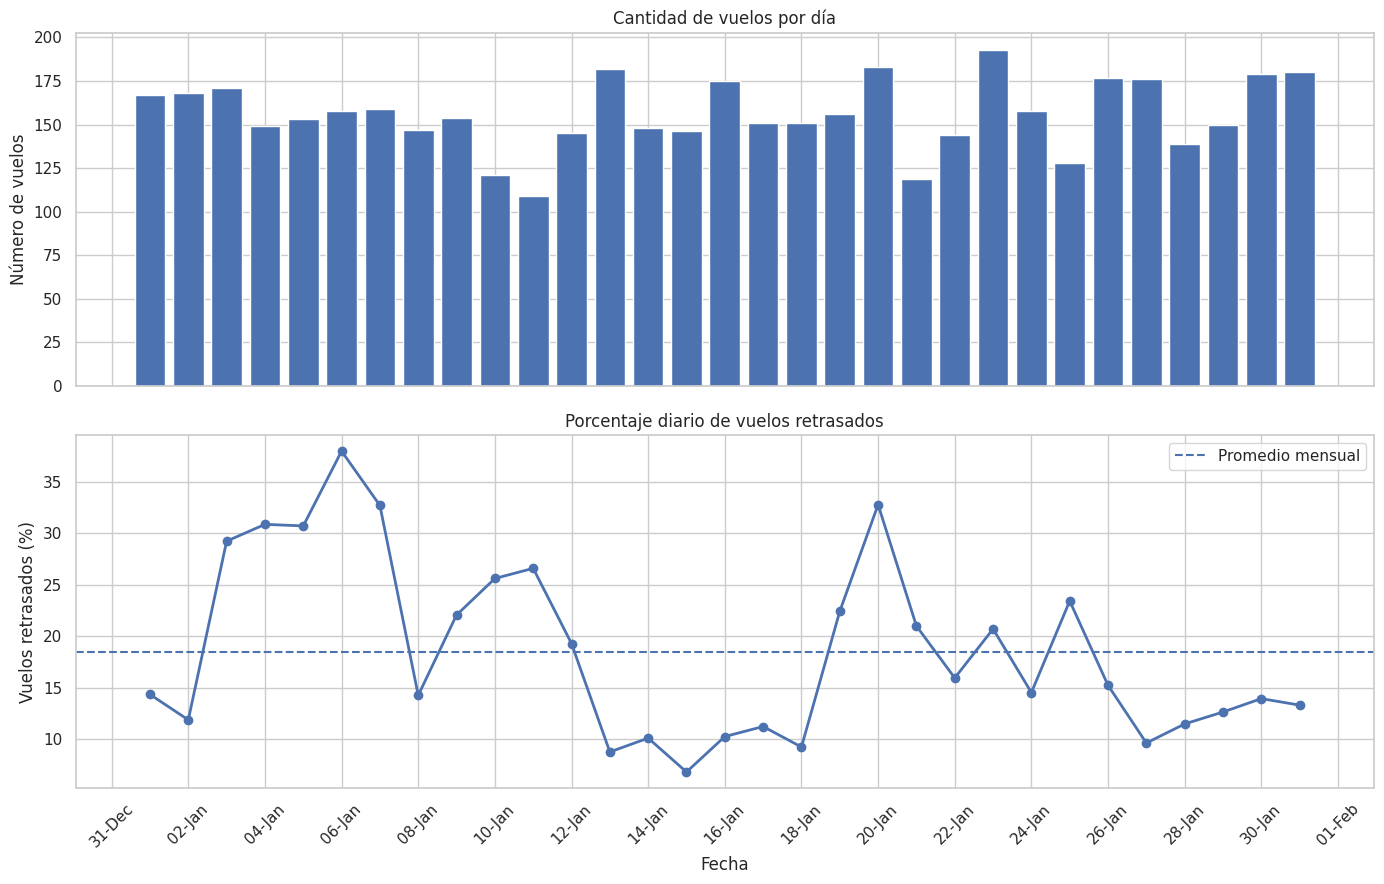


DÍAS CON MAYOR PORCENTAJE DE RETRASOS


,FlightDate,vuelos,retrasados,tasa_retraso
5,2025-01-06,158,60,37.97
19,2025-01-20,183,60,32.79
6,2025-01-07,159,52,32.70
3,2025-01-04,149,46,30.87
4,2025-01-05,153,47,30.72
2,2025-01-03,171,50,29.24
10,2025-01-11,109,29,26.61
9,2025-01-10,121,31,25.62
24,2025-01-25,128,30,23.44
18,2025-01-19,156,35,22.44


In [ ]:

# ============================================
# CELDA 15: EVOLUCIÓN DIARIA DE RETRASOS
# ============================================

df_modelo["FlightDate"] = pd.to_datetime(
    df_modelo["FlightDate"]
)

# Agrupar vuelos por fecha
retrasos_diarios = (
    df_modelo.groupby("FlightDate")
    .agg(
        vuelos=("retraso_15", "size"),
        retrasados=("retraso_15", "sum"),
        tasa_retraso=("retraso_15", "mean")
    )
    .reset_index()
    .sort_values("FlightDate")
)

retrasos_diarios["tasa_retraso"] *= 100

display(retrasos_diarios.round(2))

# Crear las gráficas
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True
)

# Gráfica 1: volumen diario
axes[0].bar(
    retrasos_diarios["FlightDate"],
    retrasos_diarios["vuelos"],
    width=0.8
)

axes[0].set_title("Cantidad de vuelos por día")
axes[0].set_ylabel("Número de vuelos")

# Gráfica 2: porcentaje de retrasos
axes[1].plot(
    retrasos_diarios["FlightDate"],
    retrasos_diarios["tasa_retraso"],
    marker="o",
    linewidth=2
)

axes[1].axhline(
    df_modelo["retraso_15"].mean() * 100,
    linestyle="--",
    label="Promedio mensual"
)

axes[1].set_title("Porcentaje diario de vuelos retrasados")
axes[1].set_ylabel("Vuelos retrasados (%)")
axes[1].set_xlabel("Fecha")
axes[1].legend()

# Formato del eje de fechas
import matplotlib.dates as mdates

axes[1].xaxis.set_major_locator(
    mdates.DayLocator(interval=2)
)

axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%d-%b")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Días con más retrasos
print("\nDÍAS CON MAYOR PORCENTAJE DE RETRASOS")

display(
    retrasos_diarios.sort_values(
        "tasa_retraso",
        ascending=False
    ).head(10).round(2)
)



,dia,vuelos,retrasados,tasa_retraso
0,Lunes,699,153,21.89
1,Martes,565,108,19.12
2,Miércoles,754,97,12.86
3,Jueves,869,137,15.77
4,Viernes,781,145,18.57
5,Sábado,537,119,22.16
6,Domingo,631,137,21.71


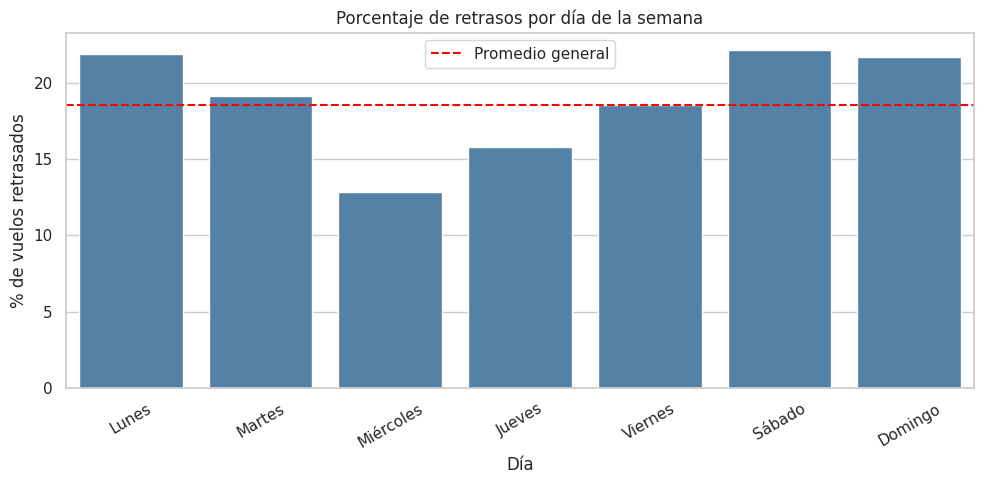

In [ ]:

# ============================================
# CELDA 16: RETRASOS POR DÍA DE LA SEMANA
# ============================================

df_modelo["dia_semana"] = (
    df_modelo["FlightDate"].dt.dayofweek
)

dias = {
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sábado",
    6: "Domingo"
}

resumen_dias = (
    df_modelo.groupby("dia_semana")
    .agg(
        vuelos=("retraso_15", "size"),
        retrasados=("retraso_15", "sum"),
        tasa_retraso=("retraso_15", "mean")
    )
    .reset_index()
)

resumen_dias["tasa_retraso"] *= 100
resumen_dias["dia"] = resumen_dias["dia_semana"].map(dias)

display(
    resumen_dias[
        ["dia", "vuelos", "retrasados", "tasa_retraso"]
    ].round(2)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=resumen_dias,
    x="dia",
    y="tasa_retraso",
    color="steelblue"
)

plt.axhline(
    df_modelo["retraso_15"].mean() * 100,
    color="red",
    linestyle="--",
    label="Promedio general"
)

plt.title("Porcentaje de retrasos por día de la semana")
plt.xlabel("Día")
plt.ylabel("% de vuelos retrasados")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

# ============================================
# CELDA 17: AMPLIACIÓN DEL HISTÓRICO
# ============================================

import pandas as pd

# Todos los meses de 2024 y 2025
periodos = [
    (anio, mes)
    for anio in [2024, 2025]
    for mes in range(1, 13)
]

N_MUESTRA_MES = 5000

calendario = pd.DataFrame(
    periodos,
    columns=["Anio", "Mes"]
)

calendario["Muestra_objetivo"] = N_MUESTRA_MES

display(calendario)

print("Meses solicitados:", len(periodos))
print(
    "Registros objetivo:",
    f"{len(periodos) * N_MUESTRA_MES:,}"
)


,Anio,Mes,Muestra_objetivo
0,2024,1,5000
1,2024,2,5000
2,2024,3,5000
3,2024,4,5000
4,2024,5,5000
5,2024,6,5000
6,2024,7,5000
7,2024,8,5000
8,2024,9,5000
9,2024,10,5000


Meses solicitados: 24
Registros objetivo: 120,000


In [ ]:

# CELDA 18: DESCARGAR 2024 Y 2025 COMPLETOS

import requests
import zipfile
import time
import pandas as pd
from pathlib import Path

RAW = Path("/content/proyecto_retrasos/raw")
RAW.mkdir(parents=True, exist_ok=True)

periodos_descarga = [
    (anio, mes)
    for anio in [2024, 2025]
    for mes in range(1, 13)
]

N_MUESTRA_MES = 5000

muestras = []
errores = []

for anio, mes in periodos_descarga:

    nombre = (
        "On_Time_Reporting_Carrier_On_Time_Performance_"
        f"1987_present_{anio}_{mes}.zip"
    )

    url = f"https://transtats.bts.gov/PREZIP/{nombre}"
    ruta = RAW / nombre

    print(f"\nProcesando {anio}-{mes:02d}...")

    try:
        inicio = time.time()

        if not ruta.exists():
            respuesta = requests.get(url, timeout=180)
            respuesta.raise_for_status()
            ruta.write_bytes(respuesta.content)
        else:
            print("Archivo existente, reutilizando.")

        with zipfile.ZipFile(ruta) as z:
            csvs = [
                n for n in z.namelist()
                if n.lower().endswith(".csv")
            ]

            if not csvs:
                raise ValueError("ZIP sin CSV")

            with z.open(csvs[0]) as archivo:
                datos = pd.read_csv(
                    archivo,
                    low_memory=False
                )

        n = min(N_MUESTRA_MES, len(datos))

        muestra = datos.sample(
            n=n,
            random_state=42
        ).copy()

        muestra["periodo_fuente"] = f"{anio}-{mes:02d}"

        muestras.append(muestra)

        print(
            f"OK: {len(datos):,} vuelos originales | "
            f"{len(muestra):,} seleccionados | "
            f"{time.time()-inicio:.1f} segundos"
        )

        del datos

    except Exception as e:
        errores.append((anio, mes, str(e)))
        print(f"ERROR: {e}")

if muestras:
    vuelos_historicos = pd.concat(
        muestras,
        ignore_index=True
    )

    ruta_salida = RAW / "muestra_historica_bts.parquet"

    vuelos_historicos.to_parquet(
        ruta_salida,
        index=False
    )

    print("\n" + "=" * 50)
    print("DESCARGA FINALIZADA")
    print("Registros:", f"{len(vuelos_historicos):,}")
    print("Meses descargados:", len(muestras))
    print("Archivo:", ruta_salida)

if errores:
    print("\nMESES CON ERRORES:")
    for error in errores:
        print(error)





Procesando 2024-01...
Archivo existente, reutilizando.
OK: 547,271 vuelos originales | 5,000 seleccionados | 10.7 segundos

Procesando 2024-02...
Archivo existente, reutilizando.
OK: 519,221 vuelos originales | 5,000 seleccionados | 10.1 segundos

Procesando 2024-03...
Archivo existente, reutilizando.
OK: 591,767 vuelos originales | 5,000 seleccionados | 10.9 segundos

Procesando 2024-04...
OK: 582,185 vuelos originales | 5,000 seleccionados | 28.1 segundos

Procesando 2024-05...
OK: 609,743 vuelos originales | 5,000 seleccionados | 27.3 segundos

Procesando 2024-06...
OK: 611,132 vuelos originales | 5,000 seleccionados | 23.0 segundos

Procesando 2024-07...
OK: 634,613 vuelos originales | 5,000 seleccionados | 28.6 segundos

Procesando 2024-08...
OK: 619,025 vuelos originales | 5,000 seleccionados | 35.3 segundos

Procesando 2024-09...
OK: 582,622 vuelos originales | 5,000 seleccionados | 24.5 segundos

Procesando 2024-10...
OK: 615,497 vuelos originales | 5,000 seleccionados | 36.6 

,anio,mes,vuelos,retrasados,tasa_retraso
0,2024,1,4837,1158,23.94
1,2024,2,4973,826,16.61
2,2024,3,4952,1005,20.29
3,2024,4,4967,984,19.81
4,2024,5,4933,1255,25.44
5,2024,6,4938,1241,25.13
6,2024,7,4855,1440,29.66
7,2024,8,4907,1177,23.99
8,2024,9,4962,784,15.80
9,2024,10,4945,717,14.50


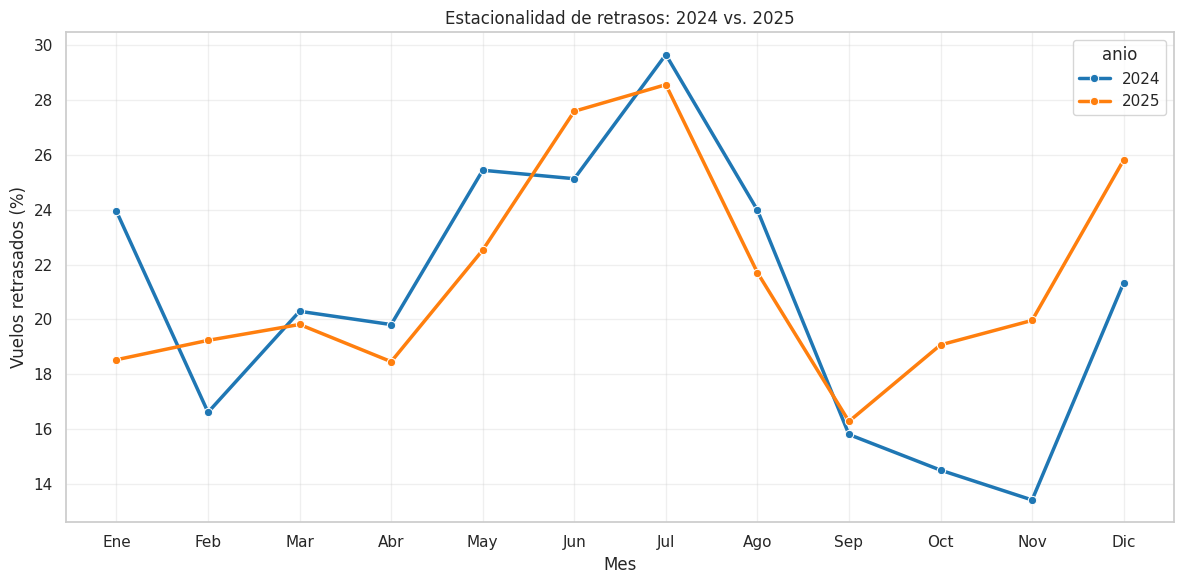


COMPARACIÓN ENTRE AÑOS


anio,2024,2025,Diferencia_2025_vs_2024
mes,,,
1,23.94,18.53,-5.41
2,16.61,19.23,2.62
3,20.29,19.81,-0.48
4,19.81,18.46,-1.35
5,25.44,22.53,-2.91
6,25.13,27.59,2.46
7,29.66,28.56,-1.10
8,23.99,21.71,-2.28
9,15.80,16.28,0.48



TOTAL DE VUELOS ANALIZADOS:
118,273

VUELOS CANCELADOS EXCLUIDOS:
1,727


In [ ]:

# ============================================
# CELDA 19: EDA DE ESTACIONALIDAD 2024-2025
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar nuestro histórico
ruta = "/content/proyecto_retrasos/raw/muestra_historica_bts.parquet"
historico = pd.read_parquet(ruta)

# Preparar variables
historico["FlightDate"] = pd.to_datetime(
    historico["FlightDate"], errors="coerce"
)

historico["Cancelled"] = pd.to_numeric(
    historico["Cancelled"], errors="coerce"
)

historico["DepDelay"] = pd.to_numeric(
    historico["DepDelay"], errors="coerce"
)

# Guardar cancelados para análisis posterior
cancelados = historico[historico["Cancelled"] == 1].copy()

# Filtrar vuelos operados con retraso conocido
eda_historico = historico[
    (historico["Cancelled"] == 0) &
    (historico["DepDelay"].notna())
].copy()

# Variable objetivo
eda_historico["retraso_15"] = (
    eda_historico["DepDelay"] >= 15
).astype(int)

eda_historico["anio"] = eda_historico["FlightDate"].dt.year
eda_historico["mes"] = eda_historico["FlightDate"].dt.month

# Resumen mensual
resumen_mensual = (
    eda_historico.groupby(["anio", "mes"])
    .agg(
        vuelos=("retraso_15", "size"),
        retrasados=("retraso_15", "sum"),
        tasa_retraso=("retraso_15", "mean")
    )
    .reset_index()
)

resumen_mensual["tasa_retraso"] *= 100

display(resumen_mensual.round(2))

# Comparación entre años
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=resumen_mensual,
    x="mes",
    y="tasa_retraso",
    hue="anio",
    marker="o",
    linewidth=2.5,
    palette="tab10"
)

plt.xticks(
    range(1, 13),
    ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
     "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
)

plt.title("Estacionalidad de retrasos: 2024 vs. 2025")
plt.xlabel("Mes")
plt.ylabel("Vuelos retrasados (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Diferencias por mes
comparacion = resumen_mensual.pivot(
    index="mes",
    columns="anio",
    values="tasa_retraso"
)

if 2024 in comparacion.columns and 2025 in comparacion.columns:
    comparacion["Diferencia_2025_vs_2024"] = (
        comparacion[2025] - comparacion[2024]
    )

print("\nCOMPARACIÓN ENTRE AÑOS")
display(comparacion.round(2))

print("\nTOTAL DE VUELOS ANALIZADOS:")
print(f"{len(eda_historico):,}")

print("\nVUELOS CANCELADOS EXCLUIDOS:")
print(f"{len(cancelados):,}")


ANÁLISIS DE ESTACIONALIDAD
---------------------------------------------
Correlación mensual entre años: 0.711
Diferencia absoluta promedio: 2.89 puntos porcentuales


anio,2024,2025,Diferencia_pp
mes,,,
1,23.94,18.53,-5.41
2,16.61,19.23,2.62
3,20.29,19.81,-0.48
4,19.81,18.46,-1.35
5,25.44,22.53,-2.91
6,25.13,27.59,2.46
7,29.66,28.56,-1.10
8,23.99,21.71,-2.28
9,15.80,16.28,0.48


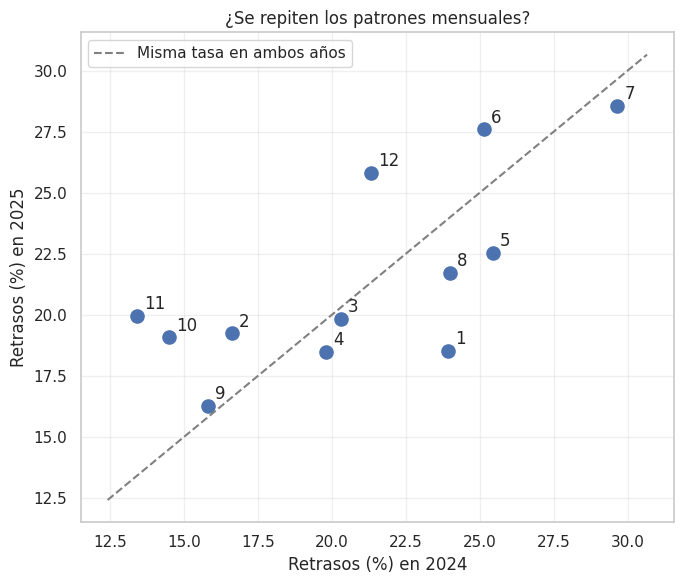

In [ ]:

# ============================================
# CELDA 20: CONSISTENCIA ESTACIONAL
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Comparar tasas mensuales de ambos años
tabla_estacional = resumen_mensual.pivot(
    index="mes",
    columns="anio",
    values="tasa_retraso"
)

tabla_estacional = tabla_estacional[[2024, 2025]].dropna()

# Correlación entre patrones mensuales
correlacion = tabla_estacional[2024].corr(
    tabla_estacional[2025]
)

# Diferencia absoluta promedio en puntos porcentuales
diferencia_promedio = (
    tabla_estacional[2025] -
    tabla_estacional[2024]
).abs().mean()

print("ANÁLISIS DE ESTACIONALIDAD")
print("-" * 45)

print(f"Correlación mensual entre años: {correlacion:.3f}")
print(
    "Diferencia absoluta promedio: "
    f"{diferencia_promedio:.2f} puntos porcentuales"
)

# Comparación mes a mes
tabla_estacional["Diferencia_pp"] = (
    tabla_estacional[2025] -
    tabla_estacional[2024]
)

display(tabla_estacional.round(2))

# Dispersión entre años
plt.figure(figsize=(7, 6))

plt.scatter(
    tabla_estacional[2024],
    tabla_estacional[2025],
    s=90
)

for mes, fila in tabla_estacional.iterrows():
    plt.annotate(
        str(mes),
        (fila[2024], fila[2025]),
        xytext=(5, 5),
        textcoords="offset points"
    )

limite_min = min(
    tabla_estacional[2024].min(),
    tabla_estacional[2025].min()
) - 1

limite_max = max(
    tabla_estacional[2024].max(),
    tabla_estacional[2025].max()
) + 1

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "--",
    color="gray",
    label="Misma tasa en ambos años"
)

plt.xlabel("Retrasos (%) en 2024")
plt.ylabel("Retrasos (%) en 2025")
plt.title("¿Se repiten los patrones mensuales?")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


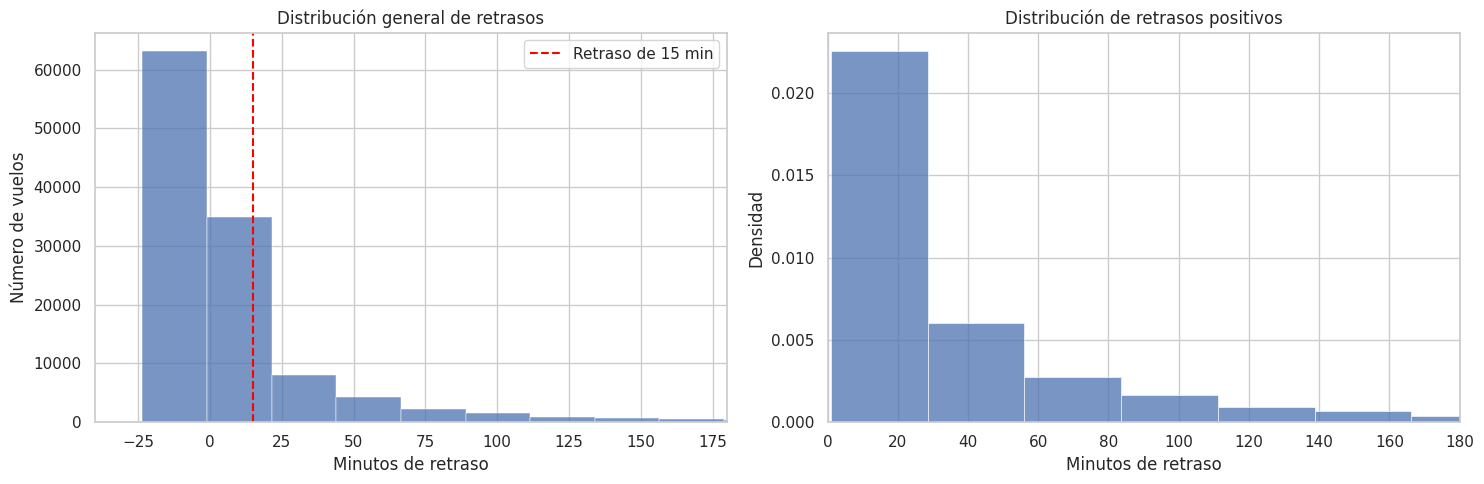

RESUMEN ESTADÍSTICO
---------------------------------------------
Vuelos analizados: 118,273
Retrasos positivos: 44,413
Media: 13.24 minutos
Mediana: -2.00 minutos
Desviación estándar: 59.61

PERCENTILES DE RETRASOS POSITIVOS


,Minutos
0.50,18.00
0.75,48.00
0.90,105.00
0.95,161.00
0.99,365.88


In [28]:

# ============================================
# CELDA 21: DISTRIBUCIÓN DE RETRASOS
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Recuperar los datos
ruta = Path(
    "/content/proyecto_retrasos/raw/muestra_historica_bts.parquet"
)

if not ruta.exists():
    raise FileNotFoundError(
        "No se encontró el histórico. "
        "Es posible que Colab haya reiniciado la sesión."
    )

df = pd.read_parquet(ruta)

# Preparar variable de retraso
df["DepDelay"] = pd.to_numeric(
    df["DepDelay"], errors="coerce"
)
df["Cancelled"] = pd.to_numeric(
    df["Cancelled"], errors="coerce"
)

# Solo vuelos operados con retraso conocido
datos = df.loc[
    (df["Cancelled"] == 0) &
    (df["DepDelay"].notna()),
    "DepDelay"
]

# Separar retrasos positivos
retrasos_positivos = datos[datos > 0]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# GRÁFICA 1: TODOS LOS RETRASOS
sns.histplot(
    datos,
    bins=100,
    ax=axes[0]
)

axes[0].axvline(
    15, color="red", linestyle="--",
    label="Retraso de 15 min"
)

axes[0].set_xlim(-40, 180)
axes[0].set_title("Distribución general de retrasos")
axes[0].set_xlabel("Minutos de retraso")
axes[0].set_ylabel("Número de vuelos")
axes[0].legend()

# GRÁFICA 2: SOLO RETRASOS POSITIVOS
sns.histplot(
    retrasos_positivos,
    bins=80,
    stat="density",
    ax=axes[1]
)

axes[1].set_xlim(0, 180)
axes[1].set_title("Distribución de retrasos positivos")
axes[1].set_xlabel("Minutos de retraso")
axes[1].set_ylabel("Densidad")

plt.tight_layout()
plt.show()

print("RESUMEN ESTADÍSTICO")
print("-" * 45)

print(f"Vuelos analizados: {len(datos):,}")
print(f"Retrasos positivos: {len(retrasos_positivos):,}")
print(f"Media: {datos.mean():.2f} minutos")
print(f"Mediana: {datos.median():.2f} minutos")
print(f"Desviación estándar: {datos.std():.2f}")

print("\nPERCENTILES DE RETRASOS POSITIVOS")
display(
    retrasos_positivos.quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("Minutos")
)
